# Лабораторная работа № 2. Классификация пассажиров Titanic

**Цель:** предсказать `Survived` (0 — не выжил, 1 — выжил) и сравнить пять алгоритмов классификации с Dummy baseline. Работа построена по структуре предоставленного примера, с более компактными графиками и выводами.

**Основная метрика:** F1-score для класса `Survived = 1`. Дополнительно: Accuracy, Precision, Recall и матрицы ошибок.

## 1. Загрузка данных и первичный анализ

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

csv_path = Path("Titanic-Dataset.csv")
if not csv_path.exists():
    raise FileNotFoundError(
        "Файл Titanic-Dataset.csv не найден. Положите CSV в ту же папку, что и ноутбук."
    )

df = pd.read_csv(csv_path)
print("Размер датасета:", df.shape)
print("Типы столбцов:")
print(df.dtypes.to_string())
display(df.head())

Размер датасета: (891, 12)
Типы столбцов:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Пропуски по столбцам:")
print(df.isna().sum().to_string())
print("\nПолных дубликатов:", df.duplicated().sum())
print("\nРаспределение Survived:")
display(pd.DataFrame({
    "Количество": df["Survived"].value_counts().sort_index(),
    "Доля, %": (df["Survived"].value_counts(normalize=True).sort_index() * 100).round(2)
}))

Пропуски по столбцам:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2

Полных дубликатов: 0

Распределение Survived:


,Количество,"Доля, %"
Survived,,
0,549,61.62
1,342,38.38


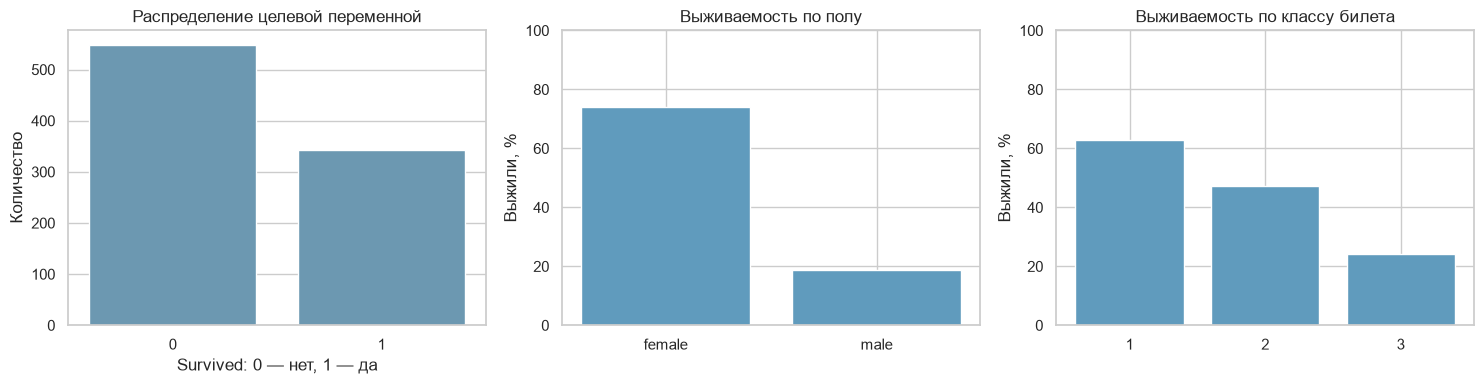

In [3]:
# Три наглядных графика вместо нескольких больших блоков из примера
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="Survived", color="#609BBD", ax=axes[0])
axes[0].set_title("Распределение целевой переменной")
axes[0].set_xlabel("Survived: 0 — нет, 1 — да")
axes[0].set_ylabel("Количество")

for ax, col, title in [
    (axes[1], "Sex", "Выживаемость по полу"),
    (axes[2], "Pclass", "Выживаемость по классу билета")
]:
    rates = df.groupby(col)["Survived"].mean().mul(100)
    positions = np.arange(len(rates))
    ax.bar(positions, rates.to_numpy(), color="#609BBD")
    ax.set_xticks(positions)
    ax.set_xticklabels([str(v) for v in rates.index])
    ax.set_ylabel("Выжили, %")
    ax.set_ylim(0, 100)
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Краткий вывод.** Данные содержат числовые и категориальные признаки. Пропуски есть прежде всего в `Age` и `Cabin`. Целевая переменная несбалансирована: погибших больше, чем выживших. На графиках заметна связь выживаемости с полом и классом билета.

## 2. Подготовка данных

Исключаем `PassengerId`, `Name`, `Ticket` и `Cabin`: идентификаторы могут способствовать запоминанию отдельных пассажиров, а `Cabin` имеет слишком много пропусков. `Sex` кодируем как 0/1, `Embarked` — One-Hot Encoding, `Age` заполняем медианой, `Embarked` — модой.


In [4]:
selected_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = df[selected_features].copy()
y = df["Survived"].copy()

# У Sex всего две известные категории: это фиксированное кодирование,
# не требующее вычисления статистик по данным.
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

numeric_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Embarked"]

preprocessor = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Доля выживших на Train:", round(y_train.mean(), 3))
print("Доля выживших на Test:", round(y_test.mean(), 3))

Train: (712, 7) | Test: (179, 7)
Доля выживших на Train: 0.383
Доля выживших на Test: 0.385


**Масштабирование.** Для SVM и KNN добавляем `StandardScaler`, поскольку они чувствительны к расстояниям между объектами. Дереву решений, случайному лесу и градиентному бустингу масштабирование не требуется. Параметры преобразований оцениваются только по Train.

## 3. Baseline и функция оценки

`DummyClassifier` всегда предсказывает наиболее частый класс. Он нужен как простая точка отсчёта. Для каждого алгоритма считаем Accuracy, Precision, Recall, F1 и Confusion Matrix.

In [20]:
results = []
predictions = {}
fitted_models = {}

def train_and_evaluate(model, X_train, X_test, y_train, y_test, model_name):
    """Обучить модель на Train и единожды получить метрики на Test."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    scores = {
        "Модель": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
    }
    results.append(scores)
    predictions[model_name] = y_pred
    fitted_models[model_name] = model
    print("\n" + "=" * 55)
    print("Модель:", model_name)
    for metric in ("Accuracy", "Precision", "Recall", "F1-score"):
        print(f"{metric:10s}: {scores[metric]:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    return scores

dummy_clf = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy_results = train_and_evaluate(
    dummy_clf, X_train, X_test, y_train, y_test, "Dummy baseline"
)


Модель: Dummy baseline
Accuracy  : 0.6145
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000
Confusion Matrix:
 [[110   0]
 [ 69   0]]


## 4. Обучение пяти моделей



### 4.1. Decision Tree

Дерево принимает решения через последовательные условия по признакам. Большая глубина позволяет находить сложные зависимости, но увеличивает риск переобучения.

In [6]:
dt_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=15))
])
dt_results = train_and_evaluate(
    dt_model, X_train, X_test, y_train, y_test, "Decision Tree"
)


Модель: Decision Tree
Accuracy  : 0.8212
Precision : 0.7937
Recall    : 0.7246
F1-score  : 0.7576
Confusion Matrix:
 [[97 13]
 [19 50]]
Classification Report:
               precision    recall  f1-score   support

Не выжил (0)       0.84      0.88      0.86       110
   Выжил (1)       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



### 4.2. Random Forest

Случайный лес объединяет множество деревьев, уменьшая зависимость результата от одного конкретного дерева.

In [7]:
rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, max_depth=10
    ))
])
rf_results = train_and_evaluate(
    rf_model, X_train, X_test, y_train, y_test, "Random Forest"
)


Модель: Random Forest
Accuracy  : 0.8268
Precision : 0.8276
Recall    : 0.6957
F1-score  : 0.7559
Confusion Matrix:
 [[100  10]
 [ 21  48]]
Classification Report:
               precision    recall  f1-score   support

Не выжил (0)       0.83      0.91      0.87       110
   Выжил (1)       0.83      0.70      0.76        69

    accuracy                           0.83       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.83      0.83      0.82       179



### 4.3. Gradient Boosting

Градиентный бустинг последовательно обучает деревья: новые деревья помогают исправлять ошибки предыдущих.

In [8]:
gb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingClassifier(
        n_estimators=100, random_state=RANDOM_STATE, max_depth=10
    ))
])
gb_results = train_and_evaluate(
    gb_model, X_train, X_test, y_train, y_test, "Gradient Boosting"
)


Модель: Gradient Boosting
Accuracy  : 0.8101
Precision : 0.7692
Recall    : 0.7246
F1-score  : 0.7463
Confusion Matrix:
 [[95 15]
 [19 50]]
Classification Report:
               precision    recall  f1-score   support

Не выжил (0)       0.83      0.86      0.85       110
   Выжил (1)       0.77      0.72      0.75        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



### 4.4. Support Vector Machine (SVM)

SVM с RBF-ядром строит нелинейную границу между классами. Масштабирование входит в `Pipeline`.

In [9]:
svm_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", random_state=RANDOM_STATE, C=1.0))
])
svm_results = train_and_evaluate(
    svm_model, X_train, X_test, y_train, y_test, "SVM (scaled)"
)


Модель: SVM (scaled)
Accuracy  : 0.8101
Precision : 0.8431
Recall    : 0.6232
F1-score  : 0.7167
Confusion Matrix:
 [[102   8]
 [ 26  43]]
Classification Report:
               precision    recall  f1-score   support

Не выжил (0)       0.80      0.93      0.86       110
   Выжил (1)       0.84      0.62      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179



### 4.5. K-Nearest Neighbors (KNN)

KNN определяет класс по ближайшим соседям. Без масштабирования, например, стоимость билета может сильнее влиять на расстояние, чем остальные признаки.

In [10]:
knn_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])
knn_results = train_and_evaluate(
    knn_model, X_train, X_test, y_train, y_test, "KNN (scaled)"
)


Модель: KNN (scaled)
Accuracy  : 0.8156
Precision : 0.8000
Recall    : 0.6957
F1-score  : 0.7442
Confusion Matrix:
 [[98 12]
 [21 48]]
Classification Report:
               precision    recall  f1-score   support

Не выжил (0)       0.82      0.89      0.86       110
   Выжил (1)       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



## 5. Матрицы ошибок

Строки — истинные классы, столбцы — предсказанные. **FP:** предсказано «выжил», но пассажир погиб. **FN:** предсказано «не выжил», но пассажир выжил. Вместо отдельного рисунка для каждой модели объединим их в одну компактную сетку.

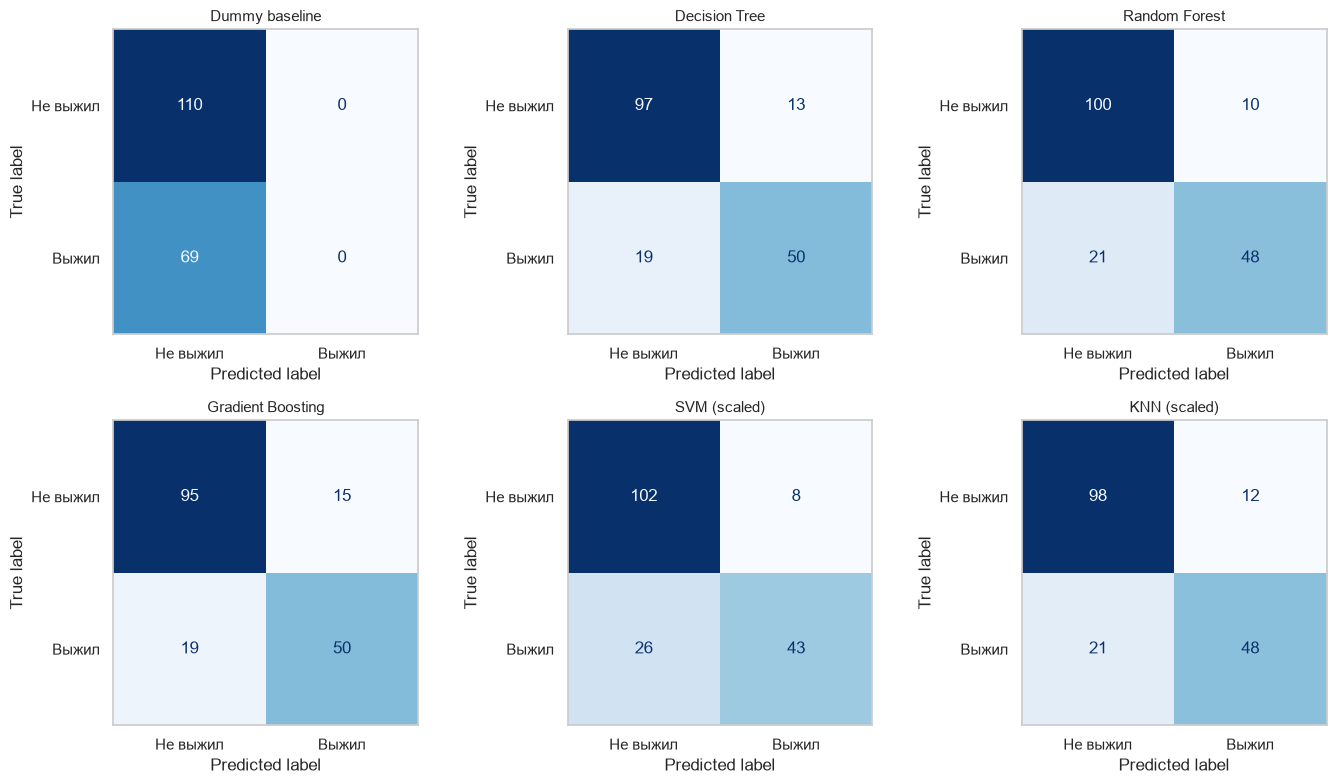

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, model_name in zip(axes.flat, predictions):
    cm = confusion_matrix(y_test, predictions[model_name], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Не выжил", "Выжил"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(model_name, fontsize=11)
    ax.grid(False)
plt.tight_layout()
plt.show()

## 6. Проверка переобучения Decision Tree

Как в образце, сопоставим Accuracy на обучении и тесте. Большой разрыв — признак возможного переобучения.

In [12]:
train_acc = dt_model.score(X_train, y_train)
test_acc = dt_model.score(X_test, y_test)
gap = train_acc - test_acc

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Разница:        {gap:.4f}")

if gap > 0.10:
    print("Вывод: заметные признаки переобучения.")
elif gap > 0.05:
    print("Вывод: есть некоторый разрыв между Train и Test.")
else:
    print("Вывод: большого разрыва Train–Test не обнаружено.")

Train Accuracy: 0.9635
Test Accuracy:  0.8212
Разница:        0.1423
Вывод: заметные признаки переобучения.


## 7. Важность признаков: Decision Tree, Random Forest, Gradient Boosting

Для трёх древовидных моделей используем `feature_importances_`. Важности категорий после кодирования объединяем обратно по исходному признаку `Embarked`. Большая важность означает полезность для предсказания, **не доказательство причинного влияния**.

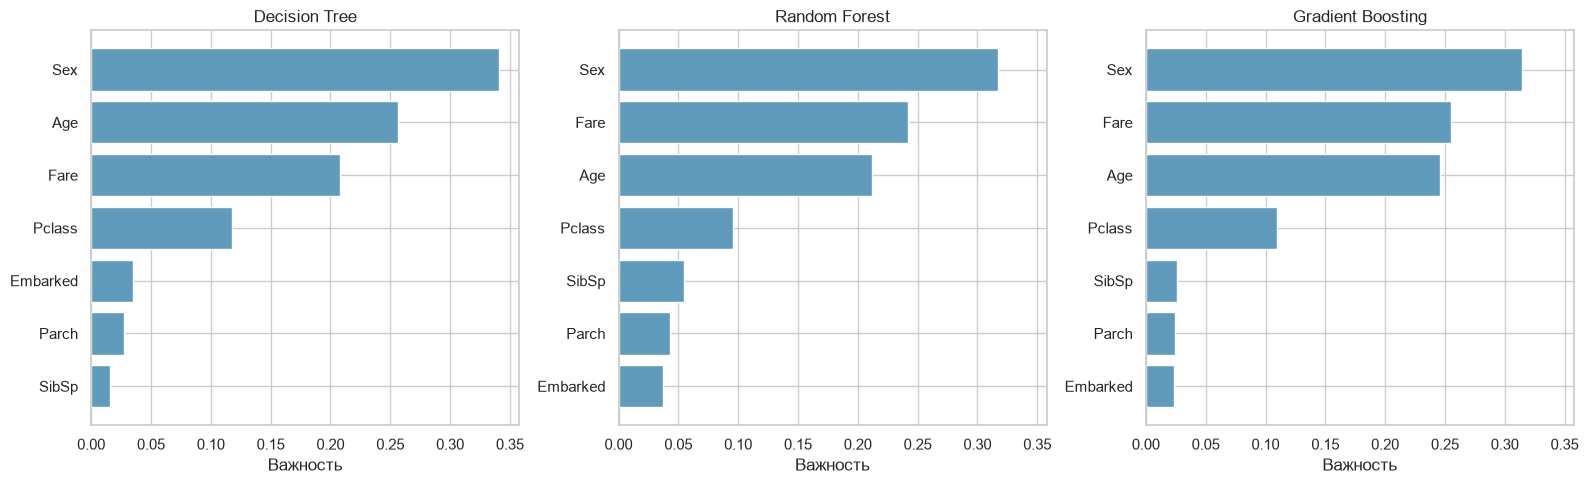

Сравнение важности исходных признаков:


,Decision Tree,Random Forest,Gradient Boosting
feature,,,
Sex,0.341,0.317,0.315
Age,0.256,0.212,0.246
Fare,0.208,0.242,0.255
Pclass,0.117,0.095,0.110
Embarked,0.035,0.037,0.024
Parch,0.027,0.043,0.024
SibSp,0.015,0.054,0.026


In [13]:
def original_feature_importance(fitted_pipeline):
    encoded_names = fitted_pipeline.named_steps["preprocessor"].get_feature_names_out()
    values = fitted_pipeline.named_steps["model"].feature_importances_
    feature_names = [
        "Embarked" if name.startswith("cat__Embarked_")
        else name.split("__", 1)[-1]
        for name in encoded_names
    ]
    importance = (
        pd.DataFrame({"feature": feature_names, "importance": values})
        .groupby("feature", as_index=False)["importance"].sum()
        .sort_values("importance", ascending=False)
    )
    return importance

importance_tables = {
    "Decision Tree": original_feature_importance(dt_model),
    "Random Forest": original_feature_importance(rf_model),
    "Gradient Boosting": original_feature_importance(gb_model),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, (name, importance) in zip(axes, importance_tables.items()):
    ax.barh(importance["feature"], importance["importance"], color="#609BBD")
    ax.invert_yaxis()
    ax.set_title(name)
    ax.set_xlabel("Важность")
plt.tight_layout()
plt.show()

importance_comparison = pd.concat([
    table.set_index("feature")["importance"].rename(name)
    for name, table in importance_tables.items()
], axis=1).fillna(0).round(3)
print("Сравнение важности исходных признаков:")
display(importance_comparison.sort_values("Decision Tree", ascending=False))

**Краткий вывод.** Важные признаки могут различаться между алгоритмами. Их полезность для предсказания согласуется с EDA, но по `feature_importances_` нельзя утверждать, что признак сам по себе является причиной выживания.

## 8. Итоговое сравнение моделей

Как в приложенном образце, строим общую таблицу из Accuracy, Precision, Recall и F1-score; отдельно отмечаем порог 0.70. Значения вычисляются автоматически, без вручную вписанных результатов.

In [14]:
leaderboard = (
    pd.DataFrame(results)
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)
leaderboard["F1 > 0.70"] = np.where(
    leaderboard["F1-score"] > 0.70, "Да", "Нет"
)
display(leaderboard.style.format({
    "Accuracy": "{:.3f}",
    "Precision": "{:.3f}",
    "Recall": "{:.3f}",
    "F1-score": "{:.3f}",
}))

main_models = leaderboard[leaderboard["Модель"] != "Dummy baseline"]
print("Моделей с F1 > 0.70:", (main_models["F1-score"] > 0.70).sum(), "из", len(main_models))
print("Лидер по тестовой F1 (описательный рейтинг):", leaderboard.iloc[0]["Модель"])
print("F1 лидера:", round(leaderboard.iloc[0]["F1-score"], 4))

,Модель,Accuracy,Precision,Recall,F1-score,F1 > 0.70
0,Decision Tree,0.821,0.794,0.725,0.758,Да
1,Random Forest,0.827,0.828,0.696,0.756,Да
2,Gradient Boosting,0.810,0.769,0.725,0.746,Да
3,KNN (scaled),0.816,0.800,0.696,0.744,Да
4,SVM (scaled),0.810,0.843,0.623,0.717,Да
5,Dummy baseline,0.615,0.000,0.000,0.000,Нет


Моделей с F1 > 0.70: 5 из 5
Лидер по тестовой F1 (описательный рейтинг): Decision Tree
F1 лидера: 0.7576


## 9. Анализ ошибок

Как в образце, разберём ошибочные предсказания наиболее результативной модели *в показанной тестовой таблице*. Рассмотрим FN и FP, несколько пассажиров и долю ошибок в группах.

In [15]:
best_name = main_models.iloc[0]["Модель"]
best_pred = predictions[best_name]
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Модель:", best_name)
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print("Всего ошибок:", fp + fn, "из", len(y_test))
print("Чаще встречаются:", "FN" if fn > fp else "FP" if fp > fn else "оба типа поровну")

# Показываем исходные, понятные человеку значения признаков.
error_analysis = df.loc[X_test.index, [
    "PassengerId", "Sex", "Pclass", "Age", "Fare", "Embarked", "Survived"
]].copy()
error_analysis["Предсказание"] = best_pred
error_analysis["Ошибка"] = error_analysis["Survived"] != error_analysis["Предсказание"]
error_analysis["Тип ошибки"] = np.select(
    [
        (error_analysis["Survived"] == 1) & (error_analysis["Предсказание"] == 0),
        (error_analysis["Survived"] == 0) & (error_analysis["Предсказание"] == 1),
    ],
    ["FN", "FP"], default="Верно"
)

print("\nПримеры ошибочно классифицированных пассажиров:")
display(error_analysis[error_analysis["Ошибка"]].head(8))

Модель: Decision Tree
TN = 97, FP = 13, FN = 19, TP = 50
Всего ошибок: 32 из 179
Чаще встречаются: FN

Примеры ошибочно классифицированных пассажиров:


,PassengerId,Sex,Pclass,Age,Fare,Embarked,Survived,Предсказание,Ошибка,Тип ошибки
553,554,male,3,22.0,7.2250,C,1,0,True,FN
559,560,female,3,36.0,17.4000,S,1,0,True,FN
536,537,male,1,45.0,26.5500,S,0,1,True,FP
712,713,male,1,48.0,52.0000,S,1,0,True,FN
455,456,male,3,29.0,7.8958,C,1,0,True,FN
502,503,female,3,NaN,7.6292,Q,0,1,True,FP
17,18,male,2,NaN,13.0000,S,1,0,True,FN
593,594,female,3,NaN,7.7500,Q,0,1,True,FP


In [16]:
error_analysis["Возрастная группа"] = pd.cut(
    error_analysis["Age"], bins=[0, 12, 18, 35, 60, np.inf],
    labels=["0–12", "13–18", "19–35", "36–60", "60+"]
).astype(object).fillna("Возраст не указан")

for col in ["Sex", "Pclass", "Возрастная группа"]:
    summary = (
        error_analysis.groupby(col, dropna=False, observed=True)["Ошибка"]
        .agg(Всего="size", Ошибок="sum", Доля_ошибок="mean")
        .sort_values("Доля_ошибок", ascending=False)
    )
    summary["Доля ошибок, %"] = (summary.pop("Доля_ошибок") * 100).round(1)
    print(f"\nОшибки по признаку {col}:")
    display(summary)


Ошибки по признаку Sex:


,Всего,Ошибок,"Доля ошибок, %"
Sex,,,
male,118,23,19.5
female,61,9,14.8



Ошибки по признаку Pclass:


,Всего,Ошибок,"Доля ошибок, %"
Pclass,,,
1,45,12,26.7
3,100,16,16.0
2,34,4,11.8



Ошибки по признаку Возрастная группа:


,Всего,Ошибок,"Доля ошибок, %"
Возрастная группа,,,
36–60,28,9,32.1
0–12,14,3,21.4
60+,6,1,16.7
19–35,74,12,16.2
Возраст не указан,40,6,15.0
13–18,17,1,5.9


## 10. Заключение

В работе проведён первичный анализ Titanic, обработаны пропуски и категориальные признаки, выполнено стратифицированное разбиение, построен Dummy baseline и обучены пять классификаторов. Результаты сравнены по Accuracy, Precision, Recall и F1, показаны матрицы ошибок, важность признаков и примеры неверных предсказаний.

**Главный результат и выполнение порога приведены в автоматически рассчитанной таблице выше.** Параметры моделей взяты из приложенного образца, а не подбирались под значения тестовой выборки. Тестовые оценки следует рассматривать как результат данной конкретной выборки.